In [1]:
import os
import sys
import json
import argparse

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib

from glob import glob
from nilearn.glm.second_level import SecondLevelModel
from nilearn.glm.second_level import make_second_level_design_matrix
from nilearn.image import threshold_img
from nilearn.glm import threshold_stats_img

In [2]:
from nilearn import plotting, datasets, surface

# for plotting slices
mni152_template = datasets.load_mni152_template(resolution=1)
# for plotting on surface
fsaverage = datasets.fetch_surf_fsaverage('fsaverage')

[fetch_surf_fsaverage] Dataset found in /ihome/bchandrasekaran/krs228/nilearn_data/fsaverage


In [3]:
task_label = 'tonecat'
fwhm = 0.00
space_label = 'MNI152NLin2009cAsym'

# define data directories
bidsroot = os.path.join('/bgfs/bchandrasekaran/krs228/data/', 
                        'FLT/',
                        'data_denoised', #'data_bids'
                       )
nilearn_dir = os.path.join(bidsroot, 'derivatives', 'nilearn')
masks_dir = os.path.join(nilearn_dir, 'masks')
# define first-level directory where group-level inputs will be pulled from
l1_dir = os.path.join(nilearn_dir, 'level-1_fwhm-%.02f'%fwhm)

# create output directory
group_out_dir = os.path.join(nilearn_dir, 'group_fwhm-%.02f'%fwhm)
if not os.path.exists(group_out_dir):
        os.makedirs(group_out_dir)

# Second-level analyses

Based on [nilearn documentation](https://nilearn.github.io/stable/auto_examples/05_glm_second_level/plot_thresholding.html#statistical-testing-of-a-second-level-analysis)

## Build the group-level design matrix

#### Read the `participants.tsv` file from the BIDS root directory

In [4]:
participants_fpath = os.path.join(bidsroot, 'participants.tsv')
participants_df = pd.read_csv(participants_fpath, sep='\t')

# subjects to ignore (not fully processed, etc.)
ignore_subs = ['sub-FLT27',
               'sub-FLT07', # bad QA 11/14/23
               #'sub-FLT02', 'sub-FLT04', 'sub-FLT18', 'sub-FLT19',
              ]
participants_df.drop(participants_df[participants_df.participant_id.isin(ignore_subs)].index, inplace=True)

# re-sort by participant ID
participants_df.sort_values(by=['participant_id'], ignore_index=True, inplace=True)

In [5]:
print(participants_df)

   participant_id  age sex         group  FFR_id
0       sub-FLT02   21   F  non-Mandarin  1002.0
1       sub-FLT03   25   F      Mandarin  2002.0
2       sub-FLT04   21   F  non-Mandarin  1003.0
3       sub-FLT05   26   M      Mandarin  3010.0
4       sub-FLT06   21   F  non-Mandarin  3001.0
5       sub-FLT08   23   F      Mandarin  2005.0
6       sub-FLT09   30   F  non-Mandarin  3002.0
7       sub-FLT10   23   F      Mandarin  2006.0
8       sub-FLT11   20   F  non-Mandarin  1005.0
9       sub-FLT12   20   F  non-Mandarin  3004.0
10      sub-FLT13   23   F  non-Mandarin  3005.0
11      sub-FLT14   23   M  non-Mandarin  3006.0
12      sub-FLT15   22   M      Mandarin  2010.0
13      sub-FLT17   29   F      Mandarin     NaN
14      sub-FLT18   24   M      Mandarin  2016.0
15      sub-FLT19   24   M      Mandarin  2018.0
16      sub-FLT20   26   F  non-Mandarin  3008.0
17      sub-FLT21   21   M      Mandarin  2011.0
18      sub-FLT22   41   F      Mandarin  2017.0
19      sub-FLT23   

In [6]:
# create group-specific lists of subject IDs
sub_list_mand = list(participants_df.participant_id[participants_df.group=='Mandarin'])
sub_list_nman = list(participants_df.participant_id[participants_df.group=='non-Mandarin'])

In [7]:
print(sub_list_mand)

['sub-FLT03', 'sub-FLT05', 'sub-FLT08', 'sub-FLT10', 'sub-FLT15', 'sub-FLT17', 'sub-FLT18', 'sub-FLT19', 'sub-FLT21', 'sub-FLT22', 'sub-FLT23', 'sub-FLT24', 'sub-FLT26']


In [8]:
print(sub_list_nman)

['sub-FLT02', 'sub-FLT04', 'sub-FLT06', 'sub-FLT09', 'sub-FLT11', 'sub-FLT12', 'sub-FLT13', 'sub-FLT14', 'sub-FLT20', 'sub-FLT25', 'sub-FLT28', 'sub-FLT30']


#### Create design matrixes

In [10]:
# get participant IDs and their group labels
subjects_label = list(participants_df.participant_id)
groups_label = list(participants_df.group)

# make new dataframe from the group labels
design_mat_groupdiff = pd.DataFrame({'Mand': groups_label,
                                     'NMan': groups_label,
                                    }
                                   )
# convert to 1s and 0s for each group as appropriate
design_mat_groupdiff.loc[design_mat_groupdiff['Mand'] == 'Mandarin', ['Mand']] = 1
design_mat_groupdiff.loc[design_mat_groupdiff['Mand'] == 'non-Mandarin', ['Mand']] = 0
design_mat_groupdiff.loc[design_mat_groupdiff['NMan'] == 'Mandarin', ['NMan']] = 0
design_mat_groupdiff.loc[design_mat_groupdiff['NMan'] == 'non-Mandarin', ['NMan']] = 1
design_mat_groupdiff = design_mat_groupdiff.astype('int')
print(design_mat_groupdiff)

    Mand  NMan
0      0     1
1      1     0
2      0     1
3      1     0
4      0     1
5      1     0
6      0     1
7      1     0
8      0     1
9      0     1
10     0     1
11     0     1
12     1     0
13     1     0
14     1     0
15     1     0
16     0     1
17     1     0
18     1     0
19     1     0
20     1     0
21     0     1
22     1     0
23     0     1
24     0     1


In [47]:
design_mat_nman = pd.DataFrame(design_mat_groupdiff.loc[design_mat_groupdiff.NMan==1].NMan)

In [48]:
design_mat_nman

,NMan
0,1
2,1
4,1
6,1
8,1
9,1
10,1
11,1
16,1
21,1


### Get files

In [26]:
# get the beta map for the contrast of interest for each subject
contrast_label = 'fb-correct-vs-wrong'
print('contrast_label:', contrast_label)

statmap_earlythird_dict = {}
for sub_id in sub_list_nman:
    statmap_earlythird_dict[sub_id] = sorted(glob(l1_dir+f'/{sub_id}_space-{space_label}/grouped_runs/earlythird/*{contrast_label}_map-beta.nii.gz'))[0]
    
statmap_middlethird_dict = {}
for sub_id in sub_list_nman:
    statmap_middlethird_dict[sub_id] = sorted(glob(l1_dir+f'/{sub_id}_space-{space_label}/grouped_runs/middlethird/*{contrast_label}_map-beta.nii.gz'))[0]
    
statmap_latethird_dict = {}
for sub_id in sub_list_nman:
    statmap_latethird_dict[sub_id] = sorted(glob(l1_dir+f'/{sub_id}_space-{space_label}/grouped_runs/latethird/*{contrast_label}_map-beta.nii.gz'))[0]

contrast_label: fb-correct-vs-wrong


In [27]:
statmap_earlythird_dict

{'sub-FLT02': '/bgfs/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/level-1_fwhm-0.00/sub-FLT02_space-MNI152NLin2009cAsym/grouped_runs/earlythird/sub-FLT02_task-tonecat_fwhm-0.00_space-MNI152NLin2009cAsym_contrast-fb-correct-vs-wrong_map-beta.nii.gz',
 'sub-FLT04': '/bgfs/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/level-1_fwhm-0.00/sub-FLT04_space-MNI152NLin2009cAsym/grouped_runs/earlythird/sub-FLT04_task-tonecat_fwhm-0.00_space-MNI152NLin2009cAsym_contrast-fb-correct-vs-wrong_map-beta.nii.gz',
 'sub-FLT06': '/bgfs/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/level-1_fwhm-0.00/sub-FLT06_space-MNI152NLin2009cAsym/grouped_runs/earlythird/sub-FLT06_task-tonecat_fwhm-0.00_space-MNI152NLin2009cAsym_contrast-fb-correct-vs-wrong_map-beta.nii.gz',
 'sub-FLT09': '/bgfs/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn/level-1_fwhm-0.00/sub-FLT09_space-MNI152NLin2009cAsym/grouped_runs/earlythird/sub-FLT09_task-tonecat

## Early runs

In [86]:
# get the beta map for the contrast of interest for each subject
l1_fnames_nman = [sorted(glob(l1_dir+f'/{sub_id}_space-{space_label}/grouped_runs/earlythird/*{contrast_label}_map-beta.nii.gz'))[0] for sub_id in sub_list_nman]

In [87]:
len(l1_fnames_nman)

12

#### Using combined GLM, with contrast isolating non-Mandarin-speaking group

In [88]:
second_level_model = SecondLevelModel(smoothing_fwhm=4.5,).fit(l1_fnames_nman, design_matrix=design_mat_nman)

z_map = second_level_model.compute_contrast(second_level_contrast=[1], output_type='z_score')

In [89]:
# threshold the second-level stats image
alpha = 0.05
cthresh = 10
cluster_correct = None # 'fdr'

thresholded_map, zthresh = threshold_stats_img(
                            z_map,
                            alpha=alpha,
                            height_control=cluster_correct,
                            cluster_threshold=cthresh,
                            two_sided=True,
                        )

threshold=3.0 current_default=3.0 old_default=3.0


/scratch/slurm-6999579/ipykernel_3575589/3562379614.py:6: FutureWarning: From nilearn version>=0.15, the default 'threshold' will be set to 3.090232306167813.If you want to silence this warning, set the threshold to 'nilearn.glm.thresholding.DEFAULT_Z_THRESHOLD'.
  thresholded_map, zthresh = threshold_stats_img(


In [90]:
group_label = 'NMan'
z_fpath   = os.path.join(group_out_dir,
                         'group-{}_space-{}_contrast-{}_map-zstat.nii.gz'.format(group_label, space_label, contrast_label))
thr_fpath = os.path.join(group_out_dir,
                         'group-{}_space-{}_contrast-{}_alpha-{}_correct-{}_cthresh-{}_map-zstat.nii.gz'.format(group_label, space_label, 
                                                                                                                contrast_label, alpha, 
                                                                                                                cluster_correct, cthresh))

#nib.save(z_map, z_fpath)
#nib.save(thresholded_map, thr_fpath)

In [91]:
plot_title = (f'Whole group (n={len(sub_list_nman)})\n'
              f'{contrast_label}  {cluster_correct}-corrected z map \n'
              'p < %.02f, clusters > %d voxels'%(alpha, cthresh))

The None=0.05 threshold is 3


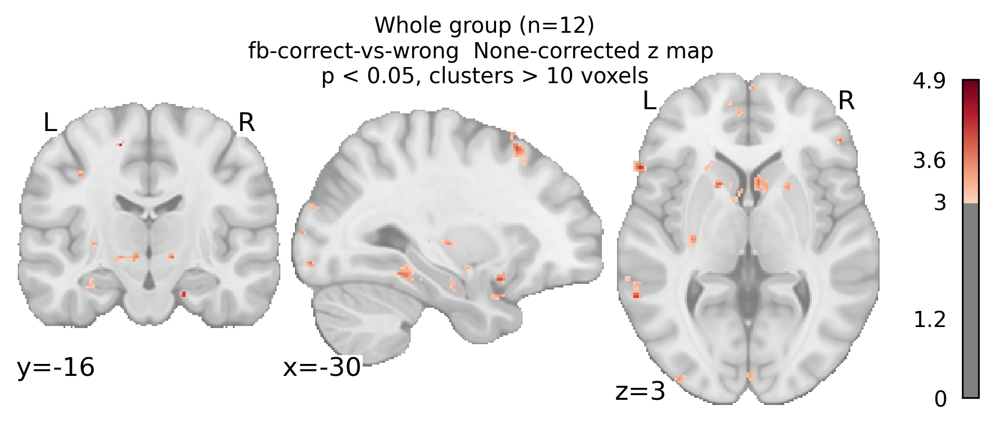

In [95]:
fig, ax = plt.subplots(figsize=(8,3), dpi=300)

plotting.plot_stat_map(
    thresholded_map, 
    threshold=zthresh,
    bg_img=mni152_template,
    black_bg=False,
    cut_coords=[-30, -16, 3],
    draw_cross=False,
    #display_mode='mosaic',
    #title=plot_title,
    axes=ax)
fig.suptitle(plot_title, fontsize=10);
print('The %s=%.3g threshold is %.3g' %(cluster_correct, alpha, zthresh))
#fig.savefig(os.path.join(group_out_dir,
#                     'group-{}_space-{}_contrast-{}_view-ortho.png'.format(group_label, space_label, contrast_label)))

Interactive viewer:

/bgfs/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.9/site-packages/numpy/core/fromnumeric.py:758: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)
/scratch/slurm-6999579/ipykernel_3575589/3829835147.py:1: UserWarning: It seems you have created more than 10 nilearn views. As each view uses dozens of megabytes of RAM, you might want to delete some of them.
  plotting.view_img(thresholded_map,



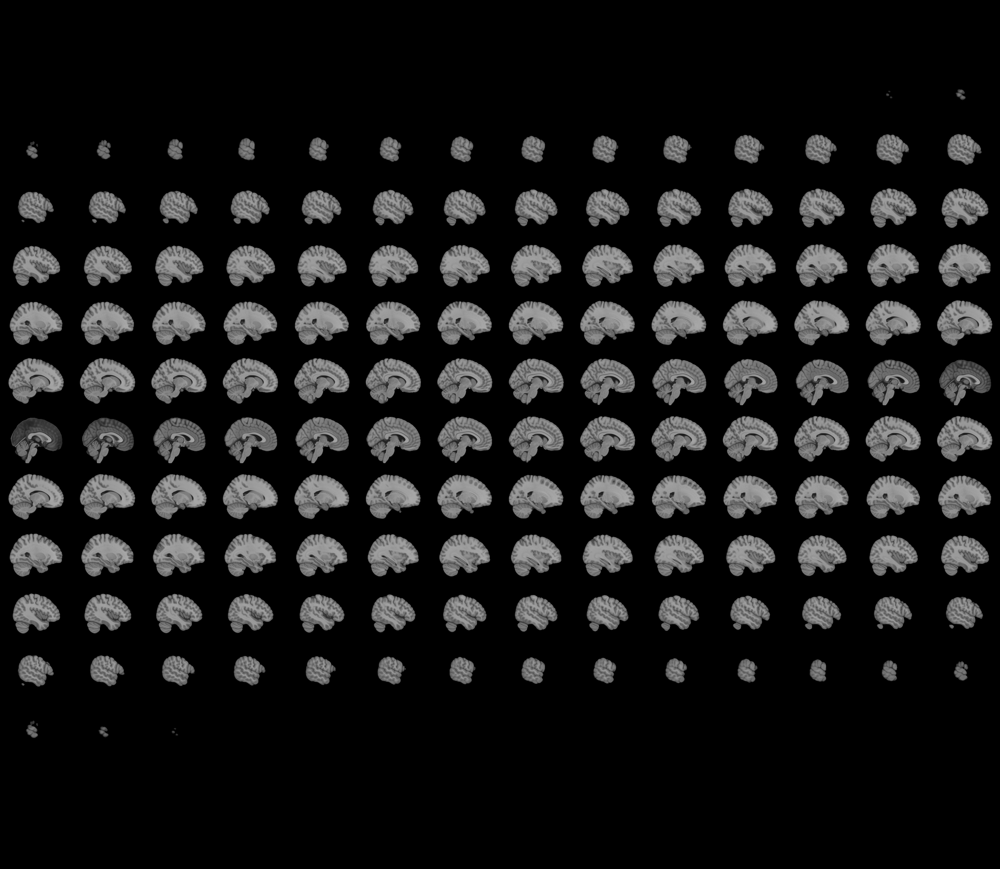
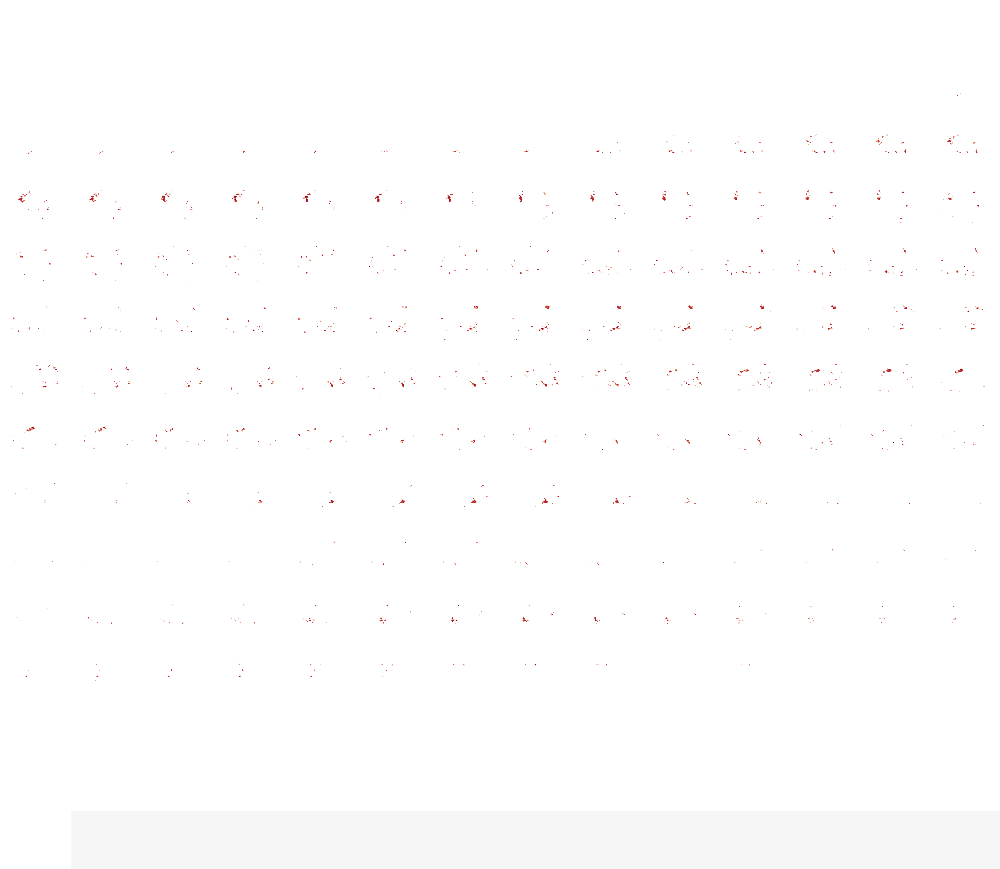

In [96]:
plotting.view_img(thresholded_map, 
                  threshold=zthresh, 
                  bg_img=mni152_template,
                  cut_coords=[-30, -16, 3],
                  title='NMan sound > baseline')

Test lower threshold:

/bgfs/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.9/site-packages/numpy/core/fromnumeric.py:758: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)
/scratch/slurm-6999579/ipykernel_3575589/29242394.py:1: UserWarning: It seems you have created more than 10 nilearn views. As each view uses dozens of megabytes of RAM, you might want to delete some of them.
  plotting.view_img(z_map,



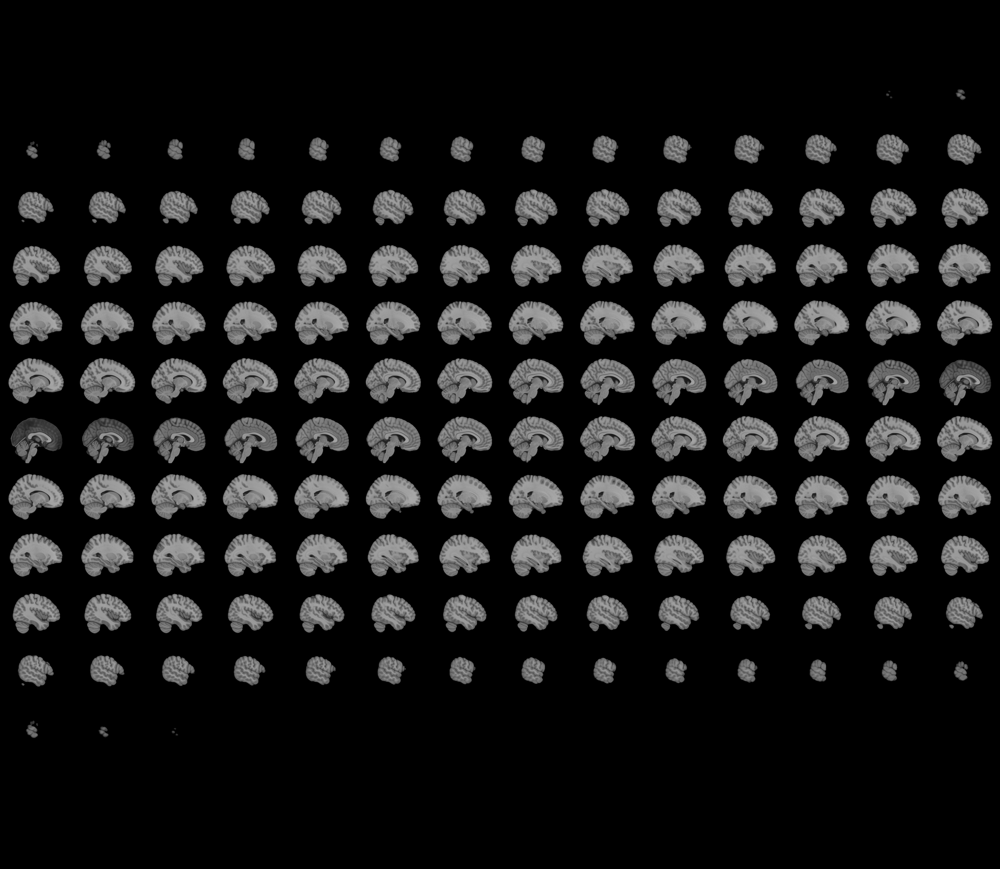
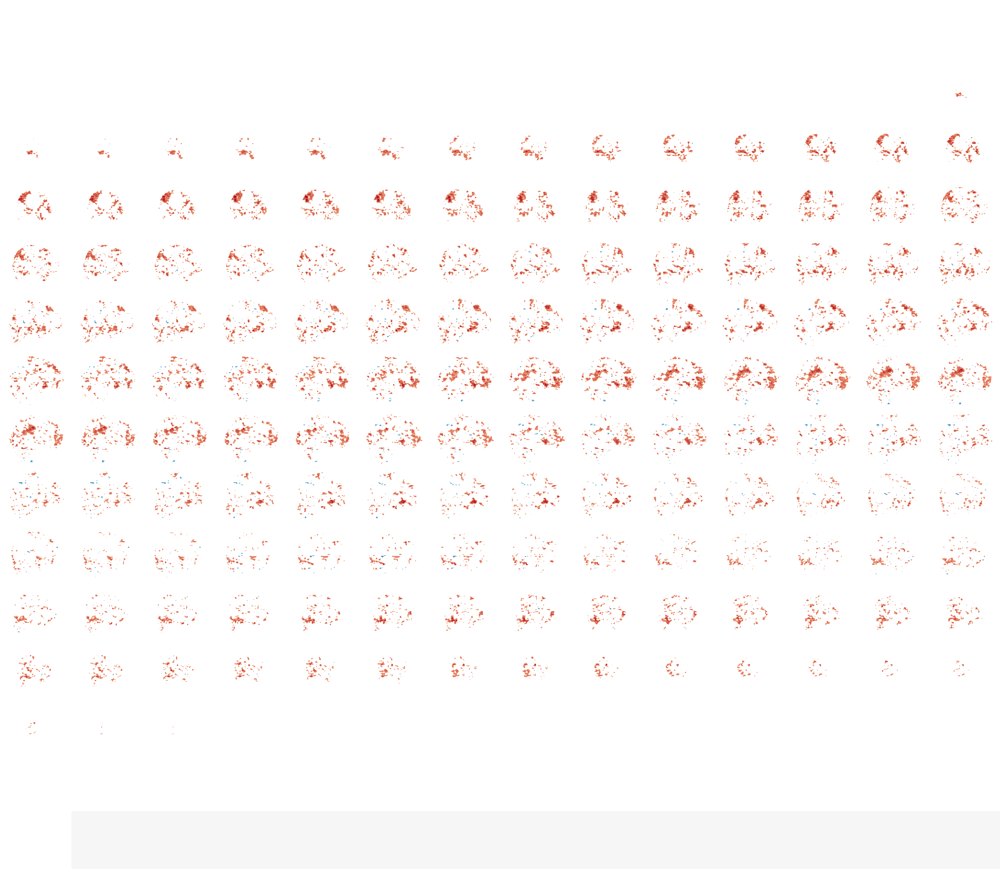

In [97]:
plotting.view_img(z_map, 
                  threshold=2, 
                  bg_img=mni152_template,
                  cut_coords=[-30, -16, 3],
                  title=f'NMan {contrast_label}')

#### Surface plots:

In [ ]:
print(plot_title)
plotting.plot_img_on_surf(thresholded_map,
                          surf_mesh='fsaverage',
                          views=['lateral', 'medial'],
                          hemispheres=['left', 'right'],
                          inflate=True,
                          threshold=zthresh,
                          colorbar=True,)
plotting.show()

#### High-res subcortical slices

In [ ]:
fig1, ax1 = plt.subplots(figsize=(5,2), dpi=300)
print(plot_title)
plotting.plot_stat_map(thresholded_map,
                       bg_img=mni152_template,
                       threshold=zthresh,
                       vmax=6,
                       cut_coords=[-10, -4, 2, 8, 14],
                       display_mode='z',
                       colorbar=False, 
                       draw_cross=False, 
                       black_bg=False,
                       axes=ax1)
#fig1.savefig(os.path.join(group_out_dir,
#                     'group-{}_space-{}_contrast-{}_view-axial-subcort.png'.format(group_label, space_label, contrast_label)))

## Final runs

In [99]:
# get the beta map for the contrast of interest for each subject
l1_fnames_nman = [sorted(glob(l1_dir+f'/{sub_id}_space-{space_label}/grouped_runs/latethird/*{contrast_label}_map-beta.nii.gz'))[0] for sub_id in sub_list_nman]

In [100]:
len(l1_fnames_nman)

12

#### Using combined GLM, with contrast isolating non-Mandarin-speaking group

In [101]:
second_level_model = SecondLevelModel(smoothing_fwhm=4.5,).fit(l1_fnames_nman, design_matrix=design_mat_nman)

z_map = second_level_model.compute_contrast(second_level_contrast=[1], output_type='z_score')

In [102]:
# threshold the second-level stats image
alpha = 0.05
cthresh = 10
cluster_correct = None # 'fdr'

thresholded_map, zthresh = threshold_stats_img(
                            z_map,
                            alpha=alpha,
                            height_control=cluster_correct,
                            cluster_threshold=cthresh,
                            two_sided=True,
                        )

threshold=3.0 current_default=3.0 old_default=3.0


/scratch/slurm-6999579/ipykernel_3575589/3562379614.py:6: FutureWarning: From nilearn version>=0.15, the default 'threshold' will be set to 3.090232306167813.If you want to silence this warning, set the threshold to 'nilearn.glm.thresholding.DEFAULT_Z_THRESHOLD'.
  thresholded_map, zthresh = threshold_stats_img(


In [ ]:
group_label = 'NMan'
z_fpath   = os.path.join(group_out_dir,
                         'group-{}_space-{}_contrast-{}_map-zstat.nii.gz'.format(group_label, space_label, contrast_label))
thr_fpath = os.path.join(group_out_dir,
                         'group-{}_space-{}_contrast-{}_alpha-{}_correct-{}_cthresh-{}_map-zstat.nii.gz'.format(group_label, space_label, 
                                                                                                                contrast_label, alpha, 
                                                                                                                cluster_correct, cthresh))

#nib.save(z_map, z_fpath)
#nib.save(thresholded_map, thr_fpath)

In [103]:
plot_title = (f'Whole group (n={len(sub_list_nman)})\n'
              f'{contrast_label}  {cluster_correct}-corrected z map \n'
              'p < %.02f, clusters > %d voxels'%(alpha, cthresh))

The None=0.05 threshold is 3


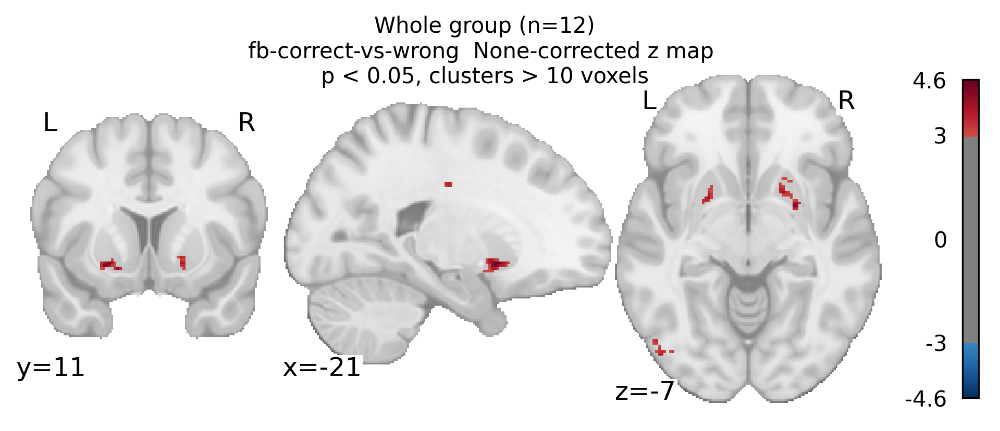

In [107]:
fig, ax = plt.subplots(figsize=(8,3), dpi=300)

plotting.plot_stat_map(
    thresholded_map, 
    threshold=zthresh,
    bg_img=mni152_template,
    black_bg=False,
    cut_coords=[-21, 11, -7],
    draw_cross=False,
    #display_mode='mosaic',
    #title=plot_title,
    axes=ax)
fig.suptitle(plot_title, fontsize=10);
print('The %s=%.3g threshold is %.3g' %(cluster_correct, alpha, zthresh))
#fig.savefig(os.path.join(group_out_dir,
#                     'group-{}_space-{}_contrast-{}_view-ortho.png'.format(group_label, space_label, contrast_label)))

Interactive viewer:

/bgfs/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.9/site-packages/numpy/core/fromnumeric.py:758: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)
/scratch/slurm-6999579/ipykernel_3575589/3829835147.py:1: UserWarning: It seems you have created more than 10 nilearn views. As each view uses dozens of megabytes of RAM, you might want to delete some of them.
  plotting.view_img(thresholded_map,



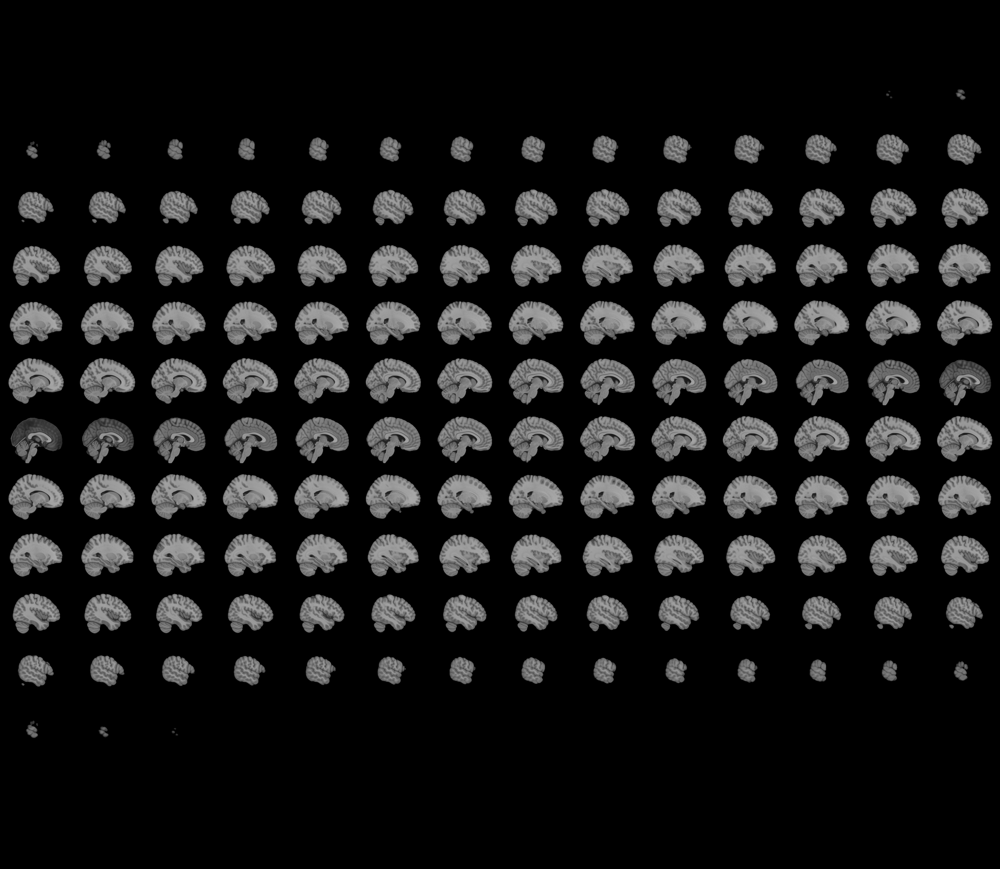
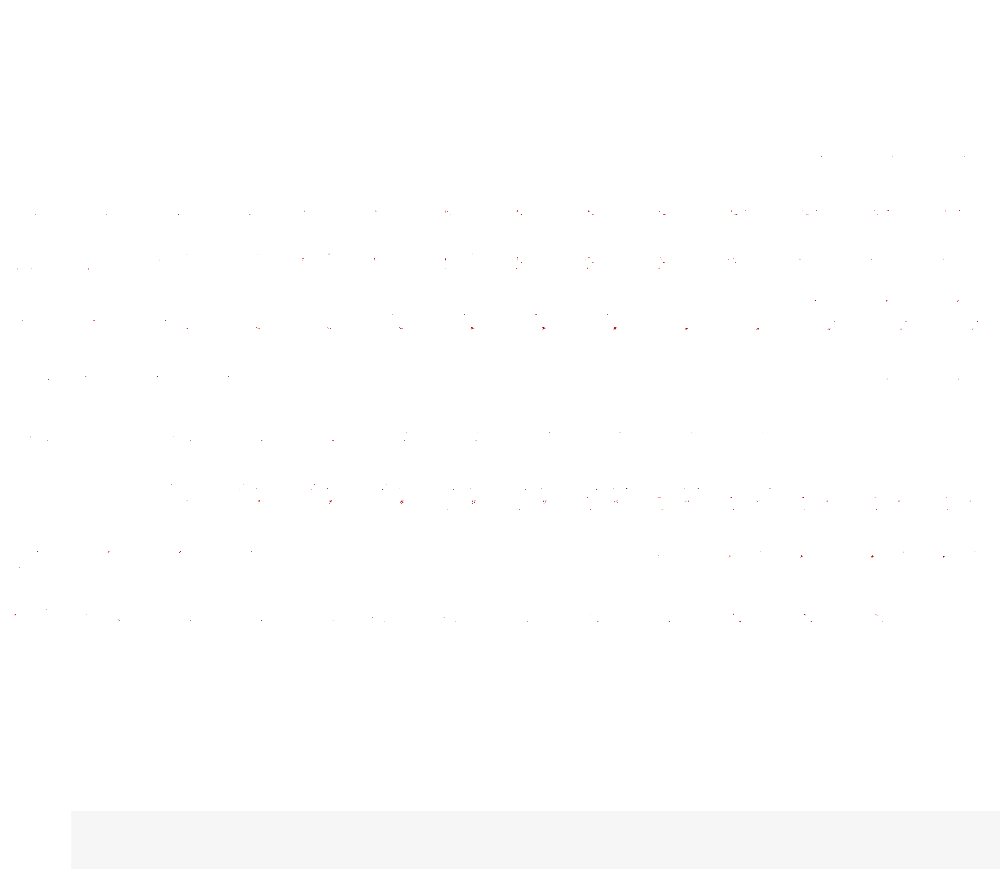

In [105]:
plotting.view_img(thresholded_map, 
                  threshold=zthresh, 
                  bg_img=mni152_template,
                  cut_coords=[-30, -16, 3],
                  title='NMan sound > baseline')

Test lower threshold:

/bgfs/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.9/site-packages/numpy/core/fromnumeric.py:758: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)
/scratch/slurm-6999579/ipykernel_3575589/29242394.py:1: UserWarning: It seems you have created more than 10 nilearn views. As each view uses dozens of megabytes of RAM, you might want to delete some of them.
  plotting.view_img(z_map,



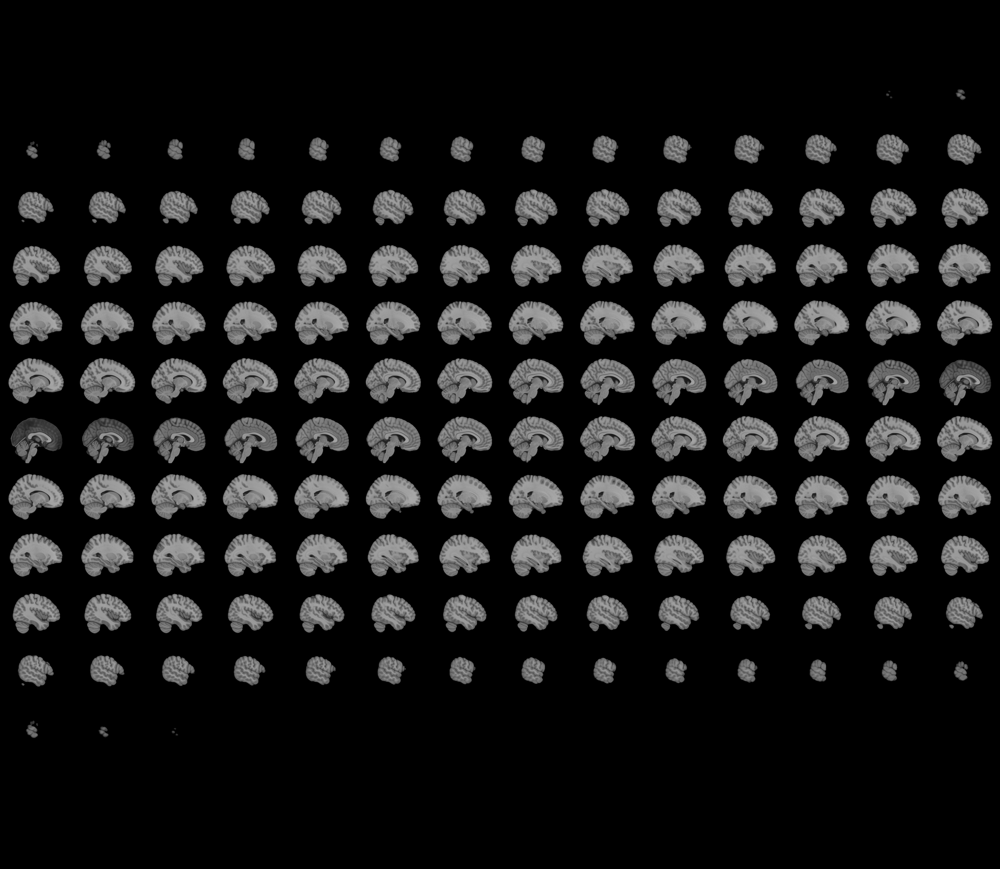
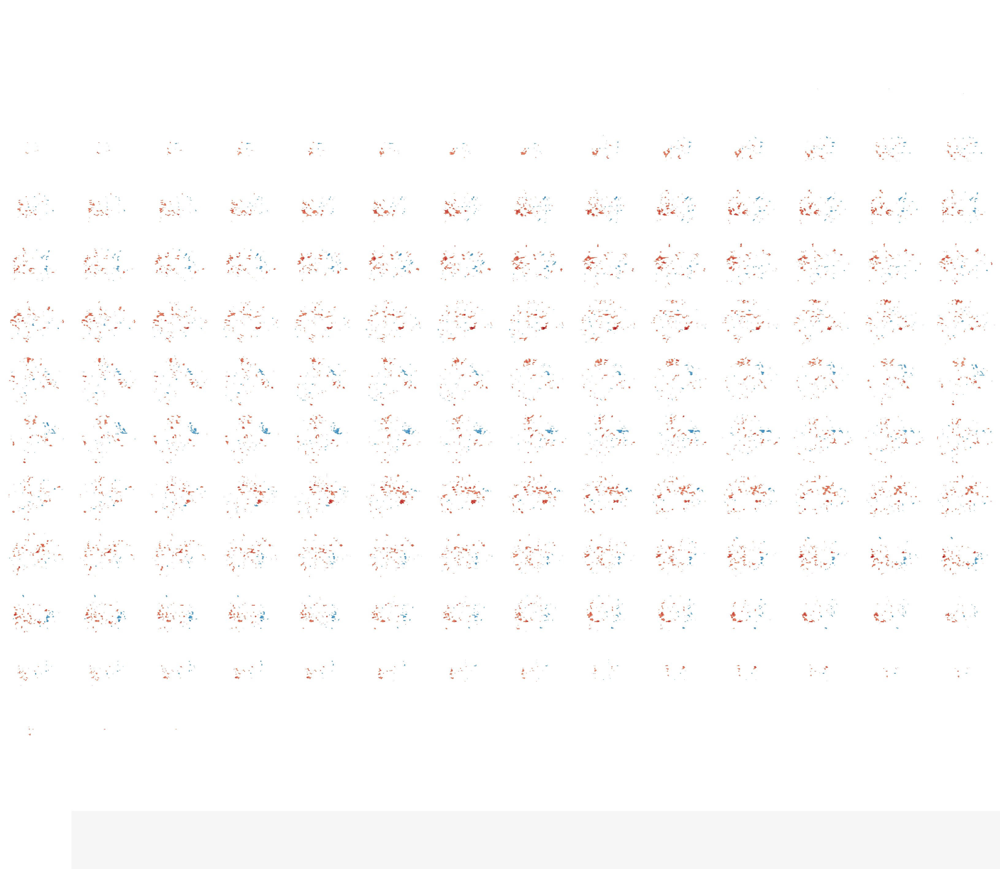

In [106]:
plotting.view_img(z_map, 
                  threshold=2, 
                  bg_img=mni152_template,
                  cut_coords=[-30, -16, 3],
                  title=f'NMan {contrast_label}')

#### Surface plots:

In [ ]:
print(plot_title)
plotting.plot_img_on_surf(thresholded_map,
                          surf_mesh='fsaverage',
                          views=['lateral', 'medial'],
                          hemispheres=['left', 'right'],
                          inflate=True,
                          threshold=zthresh,
                          colorbar=True,)
plotting.show()

#### High-res subcortical slices

In [ ]:
fig1, ax1 = plt.subplots(figsize=(5,2), dpi=300)
print(plot_title)
plotting.plot_stat_map(thresholded_map,
                       bg_img=mni152_template,
                       threshold=zthresh,
                       vmax=6,
                       cut_coords=[-10, -4, 2, 8, 14],
                       display_mode='z',
                       colorbar=False, 
                       draw_cross=False, 
                       black_bg=False,
                       axes=ax1)
fig1.savefig(os.path.join(group_out_dir,
                     'group-{}_space-{}_contrast-{}_view-axial-subcort.png'.format(group_label, space_label, contrast_label)))